# Understanding Bundle Networks

This notebook is a short, self-contained introduction to Bundle Networks (BundleNets), the generative model used in
*Exploring the Fibers of Fraud: Bundle Networks for Generating and Analyzing Fraudulent Transactions*.
BundleNets were introduced by Courts and Kvinge (ICLR 2022); the notation below follows their paper.

The notebook has four parts:

1. the problem BundleNets address: sampling from the fibers of a many-to-one map;
2. the idea behind them: fiber bundles and local trivializations;
3. a small example that trains in a few minutes on a CPU, using the implementation in `src/bundlenet.py`;
4. how the same construction is applied to a fraud detection model.

## 1. Many-to-one maps and their fibers

Most supervised learning tasks are many-to-one: many different inputs are mapped to the same output.
Suppose a model predicts the strength of a material from its processing conditions. Different conditions can produce
exactly the same strength:

| Temperature | Pressure | Strength |
|---|---|---|
| 100 °C | 50 MPa | 500 MPa |
| 150 °C | 30 MPa | 500 MPa |
| 80 °C | 70 MPa | 500 MPa |

A predictive model answers the forward question: given the conditions, what is the strength? The inverse question is
often just as useful: *which* conditions give a strength of 500 MPa, and can we generate new ones?

Formally, let $\pi : X \to Y$ be the map from inputs to outputs. For a fixed output $y$, the set of all inputs mapped to it,

$$\pi^{-1}(y) = \{x \in X : \pi(x) = y\},$$

is called the **fiber** of $\pi$ over $y$. A BundleNet is a generative model designed to sample from fibers.
In the article, $X$ is the space of card transactions, $\pi$ is the score of a fraud detection model, and the fiber over
$y$ is the set of all transactions to which the model assigns the same risk.

## 2. Fiber bundles and local trivializations

The simplest situation is a product space $X = Y \times Z$ with $\pi(y, z) = y$. Every input is a pair consisting of its
output $y$ and a second coordinate $z$ that describes everything else, and the fiber over $y$ is simply $\{y\} \times Z$.
Sampling from a fiber is then trivial: keep $y$ fixed and draw $z$.

Real data are rarely a product globally. A **fiber bundle** is a space that is a product only *locally*: over every
sufficiently small neighborhood $U$ of the base space $Y$, the part of the space lying over $U$ can be identified with
$U \times Z$. Such an identification,

$$\varphi_U : U \times Z \longrightarrow \pi^{-1}(U),$$

is called a **local trivialization**. $X$ is the *total space*, $Y$ the *base space* and $Z$ the *fiber*.

A BundleNet learns local trivializations from data:

- the base space is divided into neighborhoods $U_1, \dots, U_q$ by $k$-means clustering of the outputs, with centroids $r_1, \dots, r_q$;
- an invertible neural network $\Phi(\cdot, r_i) : X \to Y \times Z$ is trained for all neighborhoods at once; its first
  layer is an affine transformation conditioned on the centroid $r_i$, followed by RealNVP coupling blocks;
- in the **forward operation**, an input $x$ is mapped to $(y, z)$; in the **reverse operation**, a base point $y$ is paired
  with a fiber coordinate $z$ drawn from a simple fiber distribution $\mathcal{D}_Z$ and mapped back to an input lying over $y$.

The loss has a forward part, which asks the network to recover the base point of every input, and a backward part,
which compares generated and real inputs of a neighborhood as point clouds (two KL-divergence estimates and a distance term).

## 3. A small example

We use a dataset whose fibers are known exactly. Inputs are points of the plane, and the output is their distance
to the origin, $\pi(x) = \lVert x \rVert$. The fiber over $y$ is the circle of radius $y$.

In [1]:
import sys, time, warnings
warnings.filterwarnings("ignore")
sys.path.append('../src')

import numpy as np
import torch
import matplotlib.pyplot as plt
from bundlenet import BundleNet

torch.set_num_threads(8)
rng = np.random.default_rng(0)
torch.manual_seed(0)

BLUE, ORANGE, AQUA, GRAY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#c9c8c3', '#0b0b0b'
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6, 'figure.dpi': 110})

n = 3000
radius = rng.uniform(1.0, 3.0, n)
angle = rng.uniform(0, 2 * np.pi, n)
X = np.c_[radius * np.cos(angle), radius * np.sin(angle)].astype('float32')   # total space (inputs)
y = radius.astype('float32')                                                  # base points (outputs)
print('inputs', X.shape, '| base points', y.shape)

inputs (3000, 2) | base points (3000,)


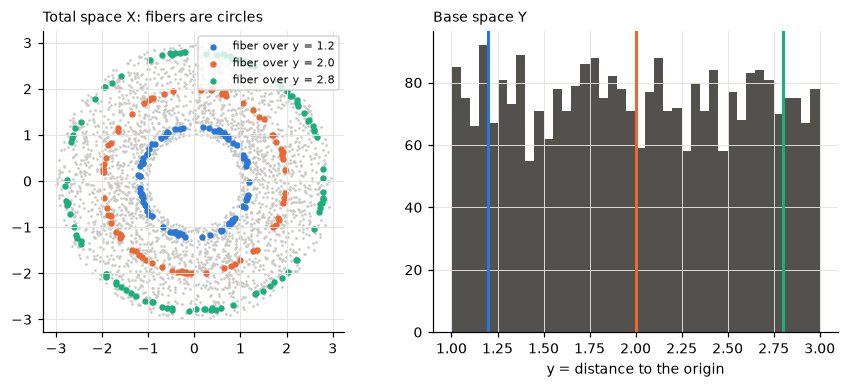

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.2, 3.6))
ax1.scatter(X[:, 0], X[:, 1], s=3, color=GRAY, linewidths=0)
for y0, col in [(1.2, BLUE), (2.0, ORANGE), (2.8, AQUA)]:
    near = np.abs(y - y0) < 0.03
    ax1.scatter(X[near, 0], X[near, 1], s=10, color=col, label=f'fiber over y = {y0}')
ax1.set_aspect('equal'); ax1.set_title('Total space X: fibers are circles', loc='left', fontsize=9)
ax1.legend(fontsize=7, loc='upper right')

ax2.hist(y, bins=40, color='#52514e')
for y0, col in [(1.2, BLUE), (2.0, ORANGE), (2.8, AQUA)]:
    ax2.axvline(y0, color=col, lw=2)
ax2.set_xlabel('y = distance to the origin'); ax2.set_title('Base space Y', loc='left', fontsize=9)
plt.tight_layout(); plt.show()

### Training a BundleNet

The base space is divided into 10 neighborhoods. Since the fibers are circles, we use one **circular prior** for the
fiber distribution $\mathcal{D}_Z$: the fiber coordinate $z$ is sampled uniformly on a circle whose radius is estimated
from the encoded data. A circle is described by two coordinates, so the network works in three dimensions (one for the
base point and two for the fiber); the two-dimensional inputs are padded with a zero, as in the original implementation.

Training takes about two minutes on a laptop CPU. The four columns printed are the forward loss (MSE) and the three
terms of the backward loss.

In [3]:
model = BundleNet(y, X, num_nbhds=10, width=64, nn_depth=2, num_circles=1, total_dim=3, seed=0)
start = time.time()
history = model.train_net(epochs=200, nbhds_per_step=5, sample_size=128, lr=1e-3, lr_halvings=3, log_every=40)
print(f'training time: {time.time() - start:.0f} s')

epoch    0 | MSE 1.7151 | KL-bwd    4.876 | KL-fwd    8.548 | Dist 1.3094


epoch   40 | MSE 0.0703 | KL-bwd    0.288 | KL-fwd    0.768 | Dist 0.1198


epoch   80 | MSE 0.0369 | KL-bwd    0.208 | KL-fwd    0.483 | Dist 0.0940


epoch  120 | MSE 0.0237 | KL-bwd    0.059 | KL-fwd    0.270 | Dist 0.0867


epoch  160 | MSE 0.0136 | KL-bwd    0.076 | KL-fwd    0.103 | Dist 0.0837


epoch  199 | MSE 0.0138 | KL-bwd    0.157 | KL-fwd    0.073 | Dist 0.0822
training time: 125 s


### Sampling from fibers

To sample from the fiber over a base point $y$, the model finds the neighborhood that contains $y$, draws fiber
coordinates $z \sim \mathcal{D}_Z$, and applies the reverse operation. The generated points should lie on the circle of
radius $y$ and cover it completely.

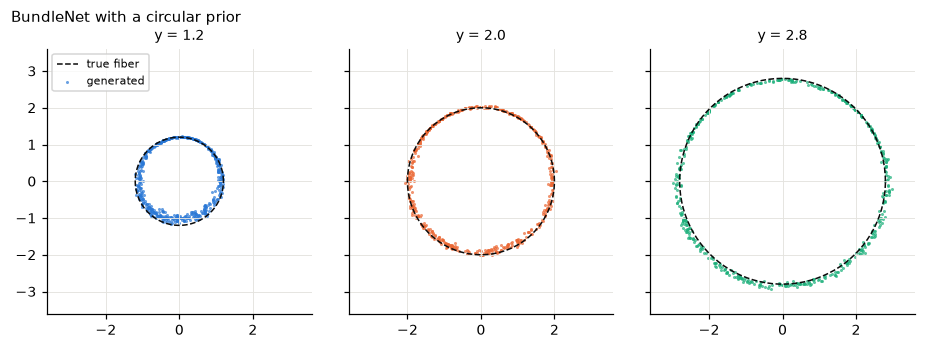

requested y = 1.2:  generated radius = 1.125 +/- 0.079
requested y = 2.0:  generated radius = 1.972 +/- 0.052
requested y = 2.8:  generated radius = 2.829 +/- 0.062


In [4]:
def show_fibers(m, title):
    fig, axes = plt.subplots(1, 3, figsize=(8.6, 3.0), sharex=True, sharey=True)
    t = np.linspace(0, 2 * np.pi, 200)
    rows = []
    for ax, (y0, col) in zip(axes, [(1.2, BLUE), (2.0, ORANGE), (2.8, AQUA)]):
        g = m.sample_from_fiber(np.array([y0]), n_per_point=500, rng=np.random.default_rng(1))
        ax.plot(y0 * np.cos(t), y0 * np.sin(t), color=INK, lw=1, ls='--', label='true fiber')
        ax.scatter(g[:, 0], g[:, 1], s=4, color=col, alpha=0.7, linewidths=0, label='generated')
        ax.set_aspect('equal'); ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 3.6)
        ax.set_title(f'y = {y0}', fontsize=9)
        r = np.linalg.norm(g[:, :2], axis=1)
        rows.append((y0, r.mean(), r.std()))
    axes[0].legend(fontsize=7, loc='upper left')
    fig.suptitle(title, x=0.02, ha='left', fontsize=10)
    plt.tight_layout(); plt.show()
    for y0, mu, sd in rows:
        print(f'requested y = {y0}:  generated radius = {mu:.3f} +/- {sd:.3f}')
    return rows

rows_circle = show_fibers(model, 'BundleNet with a circular prior')

### The choice of prior

Courts and Kvinge observe that the topology of the prior matters: a Gaussian cannot be mapped continuously and
bijectively onto a circle. We can check this here by training the same model with a one-dimensional Gaussian prior
instead of a circular one.

epoch    0 | MSE 2.3770 | KL-bwd    3.821 | KL-fwd    5.334 | Dist 0.3838


epoch   40 | MSE 0.1536 | KL-bwd    0.794 | KL-fwd    0.918 | Dist 0.1981


epoch   80 | MSE 0.0878 | KL-bwd    0.340 | KL-fwd    0.492 | Dist 0.1954


epoch  120 | MSE 0.0992 | KL-bwd    0.584 | KL-fwd    0.637 | Dist 0.1692


epoch  160 | MSE 0.0834 | KL-bwd    0.304 | KL-fwd    0.403 | Dist 0.1604


epoch  199 | MSE 0.0837 | KL-bwd    0.337 | KL-fwd    0.338 | Dist 0.1335


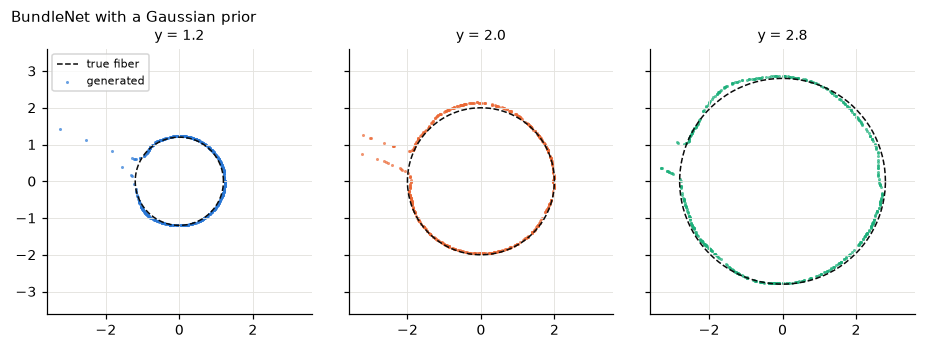

requested y = 1.2:  generated radius = 1.262 +/- 0.337
requested y = 2.0:  generated radius = 2.056 +/- 0.315
requested y = 2.8:  generated radius = 2.841 +/- 0.468


In [5]:
torch.manual_seed(0)
model_gauss = BundleNet(y, X, num_nbhds=10, width=64, nn_depth=2, num_circles=0, total_dim=2, seed=0)
model_gauss.train_net(epochs=200, nbhds_per_step=5, sample_size=128, lr=1e-3, lr_halvings=3, log_every=40)
rows_gauss = show_fibers(model_gauss, 'BundleNet with a Gaussian prior')

In [6]:
print('Spread of the generated radius around the requested base point (smaller is better)')
print(f"{'y':>5} {'circular prior':>16} {'Gaussian prior':>16}")
for (y0, _, sc), (_, _, sg) in zip(rows_circle, rows_gauss):
    print(f'{y0:>5} {sc:>16.3f} {sg:>16.3f}')

Spread of the generated radius around the requested base point (smaller is better)
    y   circular prior   Gaussian prior
  1.2            0.079            0.337
  2.0            0.052            0.315
  2.8            0.062            0.468


With the circular prior, the generated points follow the true fibers closely. With the Gaussian prior the model still
finds the right radius on average, but the fibers are noticeably thicker: the prior does not have the shape of the fiber.

## 4. From circles to fraud

The article applies exactly this construction to card transactions:

| | This notebook | The article |
|---|---|---|
| Total space $X$ | points of the plane | card transactions (29 features) |
| Map $\pi$ | distance to the origin | score of an XGBoost fraud detection model (logit scale) |
| Base space $Y$ | radii between 1 and 3 | risk scores |
| Fiber over $y$ | circle of radius $y$ | all transactions with the same risk score |
| Neighborhoods | 10 | 25 |
| Prior | one circle | 28 Gaussians |

There, the fibers are not known in advance, they live in 29 dimensions, and the fibers of interest (high-risk
transactions) contain a tiny fraction of the data. The scripts in `src/` train BundleNets and several baselines on the
credit card fraud dataset and evaluate how well each of them models these fibers; see the `README` for how to reproduce
every result.

## References

- N. Courts and H. Kvinge. *Bundle Networks: Fiber Bundles, Local Trivializations, and a Generative Approach to Exploring
  Many-to-one Maps.* International Conference on Learning Representations (ICLR), 2022. arXiv:2110.06983.
- L. Dinh, J. Sohl-Dickstein and S. Bengio. *Density Estimation using Real NVP.* ICLR, 2017.
- L. Ardizzone et al. *Framework for Easily Invertible Architectures (FrEIA).* https://github.com/vislearn/FrEIA